# EDA 01: Regular-Season Player Stats (2015-16 to 2025-26)

Exploratory data analysis of the regular-season player features built in `New-Cleaning/player-stats/`. The notebook reads **`data-files/02-processed/player_stats_combined.csv`** (from `999_combining`), so run that pipeline first.

How this notebook works:

- **Rows:** player-seasons with at least **10 regular-season games**, 5,254 of them. The saved features table keeps every player, but for describing typical stats we leave out tiny samples, as the earlier version of this EDA did.
- **Columns:** the `rs_` prefix is dropped here (`rs_ppg` → `ppg`, ...). `bpm` is Basketball-Reference Box Plus/Minus, and `plus_minus` is on-court plus/minus per game.
- **Flags, recomputed here for the EDA only:** `ppg_outlier` uses the 1.5 × IQR rule within each season. `suspicious_entry` marks a true shooting % of 0 or above 1, or more than 82 games. Rows with `suspicious_entry == True` (3 here) are left out of correlations and the trend analysis.
- We work on a copy named `eda`, and helper variables start with `eda_`.

## 1. Distributions of the performance stats

How are points, rebounds, assists, blocks, steals, minutes, games played, true shooting %, on-court plus/minus, and Box Plus/Minus distributed across player-seasons? Skewed stats matter for modeling and for which summary statistics to use.

regular-season rows (10+ games): (5254, 24)
ppg outliers: 175 | suspicious entries: 3


,Mean,Median,Std Dev,Skewness
ppg,9.358,7.709,6.301,1.110
rpg,3.788,3.283,2.393,1.362
apg,2.102,1.481,1.835,1.693
bpg,0.421,0.304,0.404,2.326
spg,0.668,0.608,0.396,0.875
mpg,20.773,20.464,8.795,-0.036
gp,52.885,57.000,20.768,-0.491
ts_pct,0.553,0.556,0.069,-0.784
plus_minus,-0.254,-0.382,2.968,0.263
bpm,-1.056,-1.100,3.154,0.095


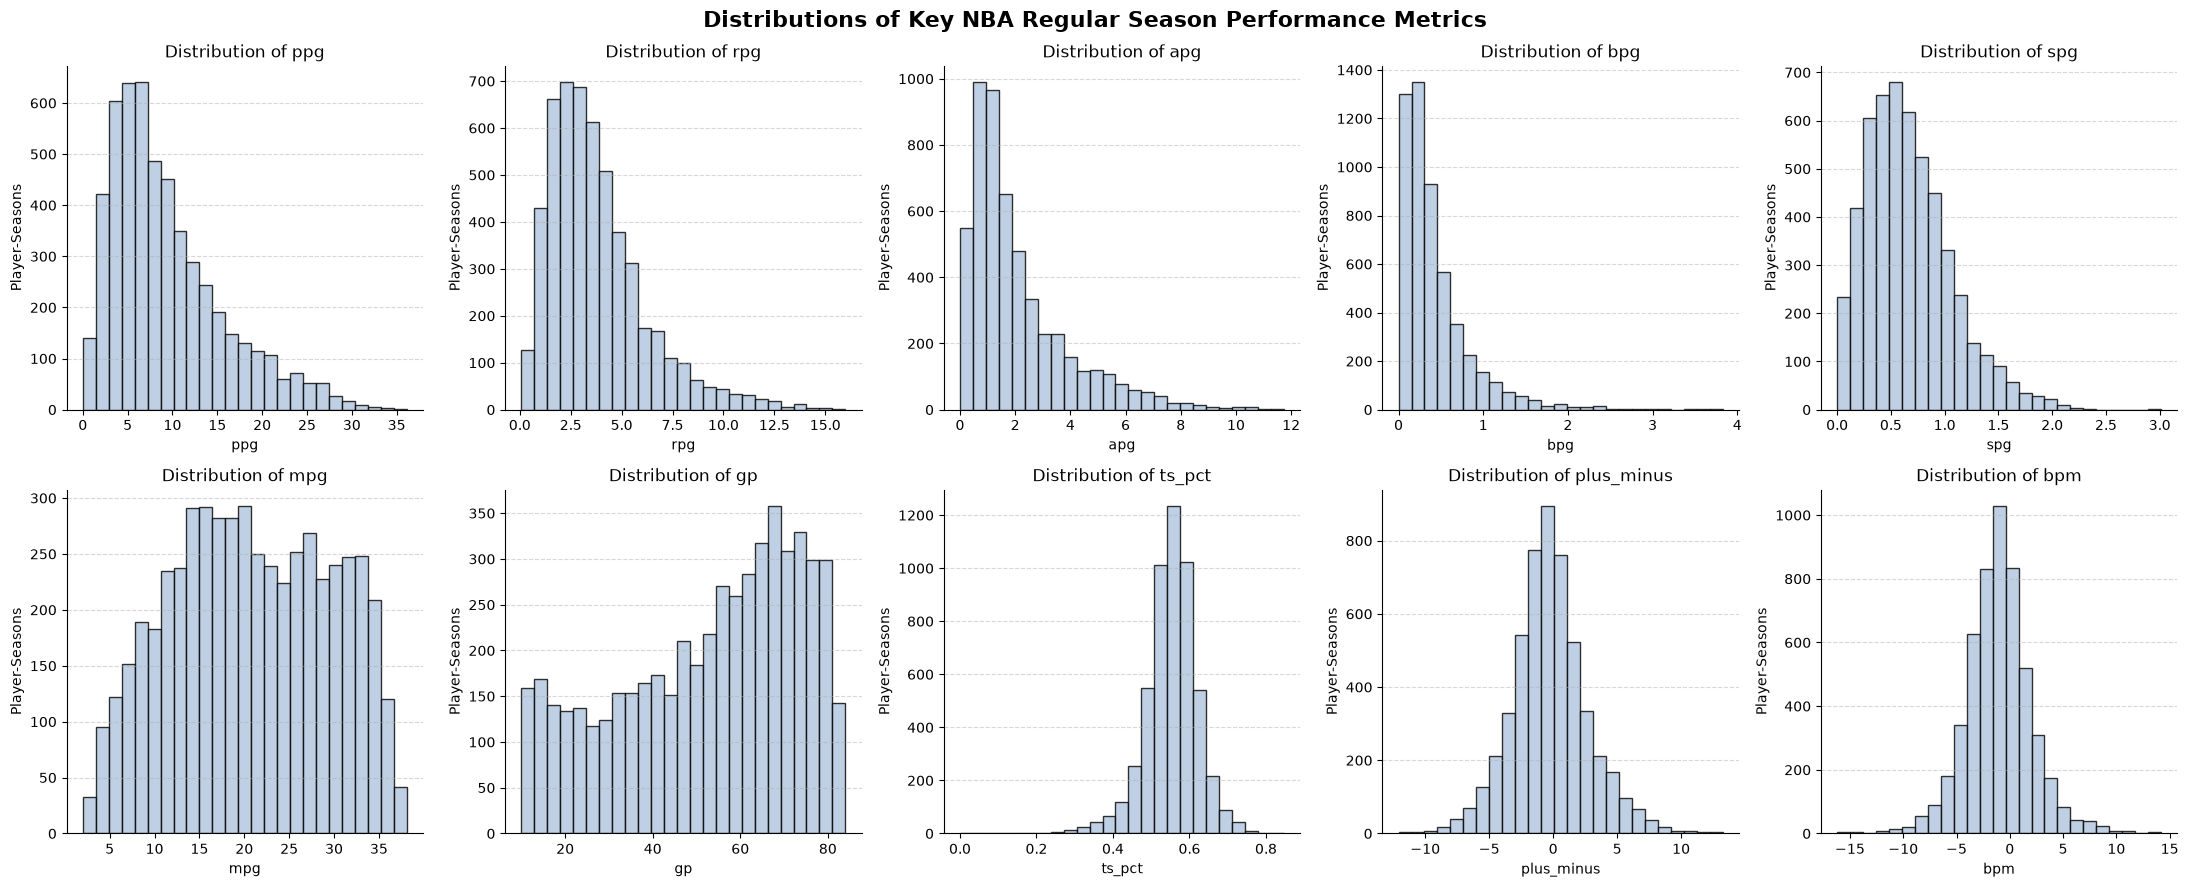

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths to the shared data-files/ folder (and the cleaning helpers) live in New-Cleaning/salary-data.
sys.path.insert(0, str(Path('..') / '..' / 'New-Cleaning' / 'salary-data'))
from nba_cleaning_utils import PROCESSED, prior_seasons_average

def flag_iqr(series):
    """True for values outside 1.5 x IQR of the series (used within each season)."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

# One table with every player feature, built by New-Cleaning/player-stats/999_combining.ipynb
stats = pd.read_csv(PROCESSED / 'player_stats_combined.csv', dtype={'nba_player_id': str})
avg_cols = ['seasons_played_last_3', 'avg_ppg_last_3', 'avg_rpg_last_3', 'avg_apg_last_3',
            'avg_bpm_last_3', 'avg_mpg_last_3', 'avg_gp_last_3']
stat_names = ['gp', 'mpg', 'ppg', 'rpg', 'apg', 'bpg', 'spg', 'ts_pct', 'bpm', 'plus_minus']

def season_view(prefix, min_gp, max_gp):
    """Rows with at least min_gp games of this season type, with plain column names and the EDA flags."""
    view = (stats[stats[f'{prefix}_gp'] >= min_gp]
            .rename(columns={'nba_player_id': 'player_id', **{f'{prefix}_{c}': c for c in stat_names}})
            [['season', 'player_id', 'player_name', 'age', 'years_in_nba'] + stat_names + avg_cols]
            .reset_index(drop=True))
    view['ppg_outlier'] = view.groupby('season')['ppg'].transform(flag_iqr)
    view['suspicious_entry'] = (view['ts_pct'].isna() | (view['ts_pct'] <= 0) | (view['ts_pct'] > 1) | (view['gp'] > max_gp))
    return view

# Regular season: 10+ games. Playoffs: 4+ games (one full series).
df_regular_clean = season_view('rs', min_gp=10, max_gp=82)
print('regular-season rows (10+ games):', df_regular_clean.shape)
print('ppg outliers:', df_regular_clean['ppg_outlier'].sum(), '| suspicious entries:', df_regular_clean['suspicious_entry'].sum())

# Create the eda copy to avoid changing df_regular_clean
eda = df_regular_clean.copy()

# Stat columns to analyze
eda_stat_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'bpm']

# Calculate descriptive statistics
eda_summary_table = pd.DataFrame({
    'Mean': eda[eda_stat_cols].mean(),
    'Median': eda[eda_stat_cols].median(),
    'Std Dev': eda[eda_stat_cols].std(),
    'Skewness': eda[eda_stat_cols].skew()
})
display(eda_summary_table.round(3))

# Plot a 2x5 grid of histograms
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.ravel()

for i, col in enumerate(eda_stat_cols):
    axes[i].hist(eda[col], bins=25, color='lightsteelblue', edgecolor='black', alpha=0.8)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Player-Seasons')
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Distributions of Key NBA Regular Season Performance Metrics', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### What we found

* **Right-skewed stats:** `bpg` (skew 2.33), `apg` (1.69), `rpg` (1.36), `ppg` (1.11), and `spg` (0.88) are right-skewed. Most players have low numbers and a few stars have very high ones, so the mean is above the median (for example, `ppg` mean 9.4 vs median 7.7).
* **Close to symmetric:** `mpg` (skew −0.04) is almost symmetric. `gp` (−0.49) and `ts_pct` (−0.78) have a longer tail on the low side, from players who miss games or shoot badly in limited minutes.
* **Plus/minus and BPM are both roughly symmetric** (skew 0.26 and 0.10) and centered just below zero (medians −0.38 and −1.10). BPM is set so that a league-average player is 0 *when weighted by minutes*. Counting every player once, the many bench players below average pull the typical value under 0.

## 2. Age and experience

How old and how experienced are players, and how do playing time and scoring change with age and experience? `years_in_nba` counts seasons since the player's first NBA game (a rookie is 1), as defined in the pipeline's notebook 01.

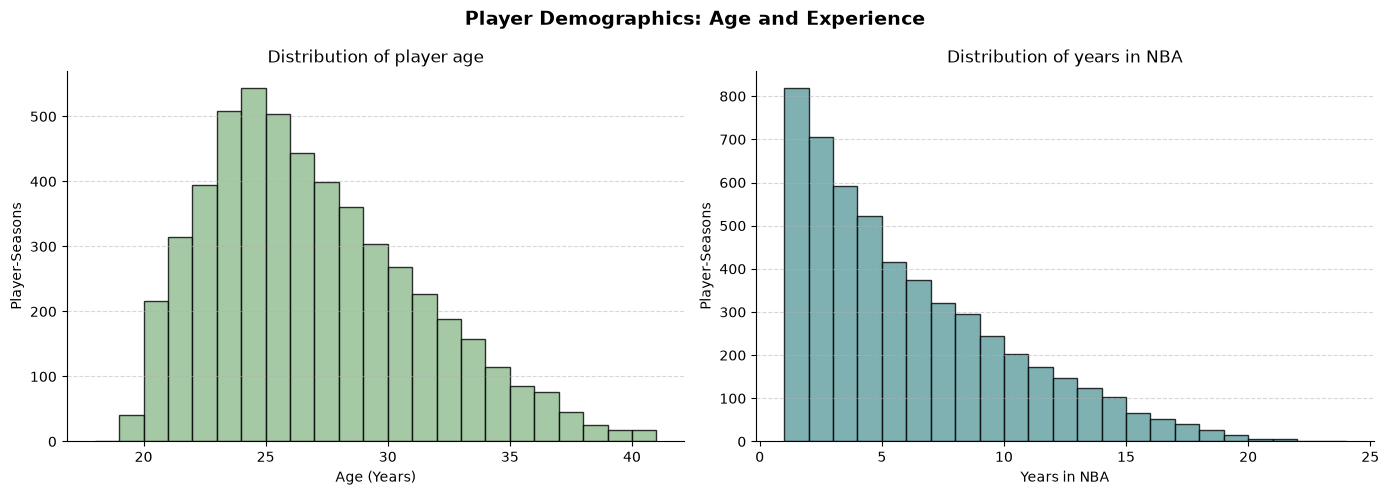

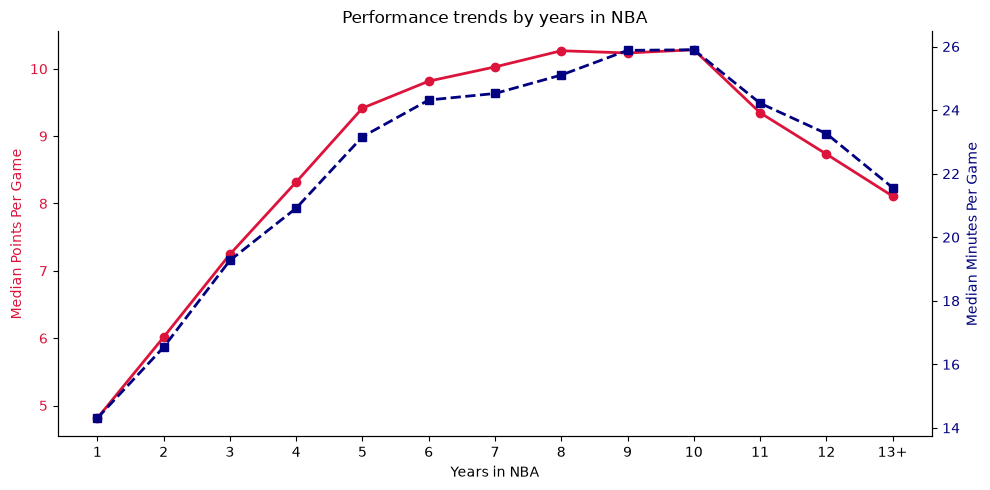

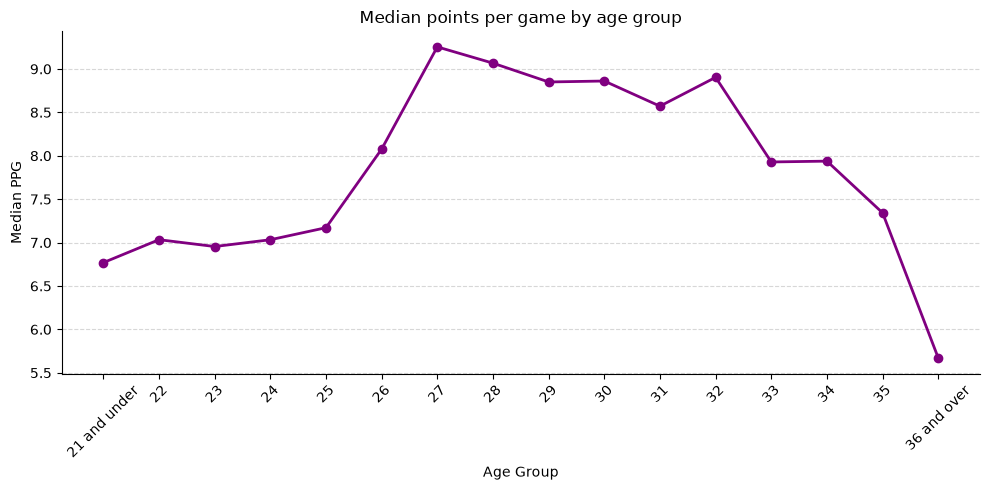

Age quartiles: [23.0, 26.0, 29.0] | years_in_nba: most common 1, median 4.0


exp_group,1,2,3,4,5,6,7,8,9,10,11,12,13+
ppg,4.81,6.02,7.25,8.32,9.42,9.82,10.03,10.27,10.24,10.28,9.35,8.73,8.11
mpg,14.31,16.54,19.27,20.91,23.16,24.32,24.52,25.10,25.88,25.90,24.22,23.26,21.56


age_group,21 and under,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36 and over
median_ppg,6.77,7.03,6.95,7.03,7.17,8.08,9.25,9.07,8.85,8.86,8.57,8.9,7.93,7.94,7.34,5.67


In [2]:
# 1. Histograms of age and years_in_nba
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(eda['age'], bins=range(18, 42), color='darkseagreen', edgecolor='black', alpha=0.8)
axes[0].set_title('Distribution of player age')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Player-Seasons')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].yaxis.grid(True, linestyle='--', alpha=0.5)

axes[1].hist(eda['years_in_nba'], bins=range(1, int(eda['years_in_nba'].max()) + 2), color='cadetblue', edgecolor='black', alpha=0.8)
axes[1].set_title('Distribution of years in NBA')
axes[1].set_xlabel('Years in NBA')
axes[1].set_ylabel('Player-Seasons')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Player Demographics: Age and Experience', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Line chart: median ppg and median mpg by years_in_nba (capped at 13+)
eda_exp = eda.copy()
eda_exp['exp_group'] = eda_exp['years_in_nba'].apply(lambda x: '13+' if x >= 13 else str(int(x)))

# Sort group keys properly
eda_exp_order = [str(i) for i in range(1, 13)] + ['13+']
eda_exp_grouped = eda_exp.groupby('exp_group')[['ppg', 'mpg']].median().reindex(eda_exp_order)

fig, ax1 = plt.subplots(figsize=(10, 5))
color = 'crimson'
ax1.set_xlabel('Years in NBA')
ax1.set_ylabel('Median Points Per Game', color=color)
ax1.plot(eda_exp_grouped.index, eda_exp_grouped['ppg'], marker='o', color=color, linewidth=2, label='Median PPG')
ax1.tick_params(axis='y', labelcolor=color)
ax1.spines['top'].set_visible(False)

ax2 = ax1.twinx()
color = 'navy'
ax2.set_ylabel('Median Minutes Per Game', color=color)
ax2.plot(eda_exp_grouped.index, eda_exp_grouped['mpg'], marker='s', linestyle='--', color=color, linewidth=2, label='Median MPG')
ax2.tick_params(axis='y', labelcolor=color)
ax2.spines['top'].set_visible(False)

plt.title('Performance trends by years in NBA')
plt.tight_layout()
plt.show()

# 3. Line chart: median ppg by age (grouped <21 and >36 into end groups)
eda_age = eda.copy()
def age_group(a):
    if a <= 21:
        return '21 and under'
    elif a >= 36:
        return '36 and over'
    else:
        return str(int(a))

eda_age['age_group'] = eda_age['age'].apply(age_group)
eda_age_order = ['21 and under'] + [str(i) for i in range(22, 36)] + ['36 and over']
eda_age_grouped = eda_age.groupby('age_group')['ppg'].median().reindex(eda_age_order)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(eda_age_grouped.index, eda_age_grouped.values, marker='o', color='purple', linewidth=2)
ax.set_title('Median points per game by age group')
ax.set_xlabel('Age Group')
ax.set_ylabel('Median PPG')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Age quartiles: {eda['age'].quantile([0.25, 0.5, 0.75]).tolist()} | years_in_nba: most common {eda['years_in_nba'].mode()[0]}, median {eda['years_in_nba'].median()}")
display(eda_exp_grouped.round(2).T)
display(eda_age_grouped.round(2).to_frame('median_ppg').T)

### What we found

* **Young league:** the middle half of player-seasons are between 23 and 29 years old (median 26). The most common `years_in_nba` is 1, and the median is 4.
* **Experience:** median `ppg` rises from 4.8 in the first year to about 10.3 in years 8-10, then falls to 8.1 for 13+ years. Median `mpg` follows the same shape: 14.3 in year 1, 25.9 in years 9-10, and 21.6 for 13+. Part of this rise is survivor bias, because weaker players leave the league early.
* **Age:** median `ppg` is about 7 for ages 21-25, rises to 8.1 at 26 and 9.3 at 27, stays between 8.6 and 9.1 from 28 to 32, and drops to 5.7 for 36 and over.
* **No estimated values anymore:** the earlier version of this EDA counted experience from the draft year and had to estimate it for undrafted players (19% of rows). Experience now comes from each player's first game in the stats table, so it is known for every row. The median dropped from 5 to 4, mostly because draft-and-stash players are no longer overcounted.

## 3. Playing time

Minutes per game measure a player's opportunity on the court. How does playing time relate to scoring, shooting efficiency, and plus/minus, and where are the scoring outliers?

,count,median_ppg,median_ts_pct,median_plus_minus
mpg_bin,,,,
0-10,683,2.300,0.518,-0.609
10-20,1848,5.421,0.545,-0.773
20-30,1719,10.127,0.562,-0.350
30+,1004,18.593,0.573,1.645


Correlation between mpg and ppg (excluding 3 suspicious rows): 0.8752
Scoring outliers: 175, lowest mpg among them: 28.87


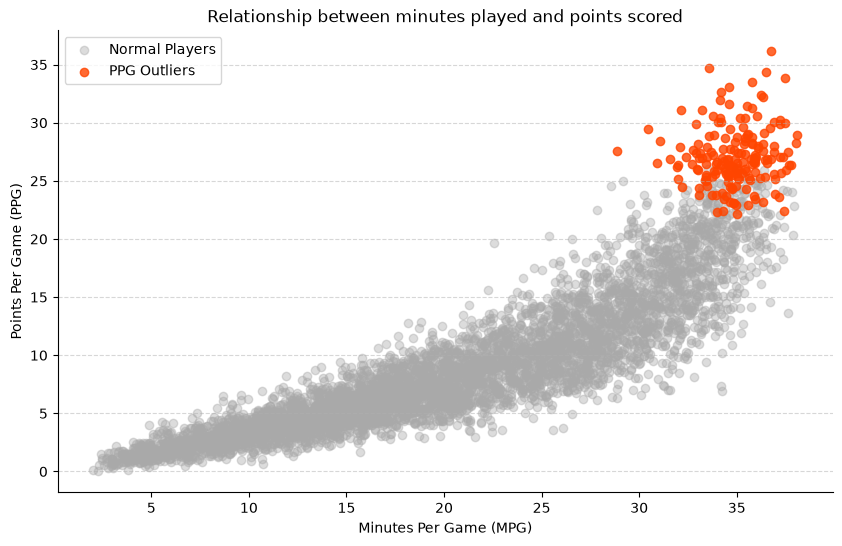

In [3]:
# Bin minutes per game
def bin_mpg(m):
    if m < 10:
        return '0-10'
    elif m < 20:
        return '10-20'
    elif m < 30:
        return '20-30'
    else:
        return '30+'

eda['mpg_bin'] = eda['mpg'].apply(bin_mpg)
eda_mpg_grouped = eda.groupby('mpg_bin').agg(
    count=('ppg', 'count'),
    median_ppg=('ppg', 'median'),
    median_ts_pct=('ts_pct', 'median'),
    median_plus_minus=('plus_minus', 'median')
).reindex(['0-10', '10-20', '20-30', '30+'])

display(eda_mpg_grouped.round(3))

# Calculate correlation between mpg and ppg (excluding suspicious entries)
eda_no_susp = eda[eda['suspicious_entry'] == False]
eda_corr_mpg_ppg = eda_no_susp['mpg'].corr(eda_no_susp['ppg'])
print(f"Correlation between mpg and ppg (excluding {eda['suspicious_entry'].sum()} suspicious rows): {eda_corr_mpg_ppg:.4f}")
print(f"Scoring outliers: {eda['ppg_outlier'].sum()}, lowest mpg among them: {eda.loc[eda['ppg_outlier'], 'mpg'].min():.2f}")

# Scatter plot of mpg vs ppg highlighting outliers
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(eda[eda['ppg_outlier'] == False]['mpg'], eda[eda['ppg_outlier'] == False]['ppg'],
           alpha=0.4, color='darkgray', label='Normal Players')
ax.scatter(eda[eda['ppg_outlier'] == True]['mpg'], eda[eda['ppg_outlier'] == True]['ppg'],
           alpha=0.8, color='orangered', label='PPG Outliers')
ax.set_title('Relationship between minutes played and points scored')
ax.set_xlabel('Minutes Per Game (MPG)')
ax.set_ylabel('Points Per Game (PPG)')
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strong link between minutes and points:** the correlation between `mpg` and `ppg` is 0.875 (without the 3 suspicious rows).
* **Bigger roles look better:** from the 0-10 minute group to the 30+ group, median `ppg` goes from 2.3 to 18.6 and median `ts_pct` from 51.8% to 57.3%. Median `plus_minus` is slightly negative for the first three groups (−0.61, −0.77, −0.35) and positive only for 30+ minutes (+1.65).
* **Scoring outliers:** all 175 scoring outliers play at least 28.9 minutes per game, so scoring far above a season's typical level takes a starter's minutes.

## 4. Relationships between variables

Correlations between the performance stats, age, and experience, to spot collinearity and to see how scoring relates to overall impact (on-court plus/minus and Box Plus/Minus).

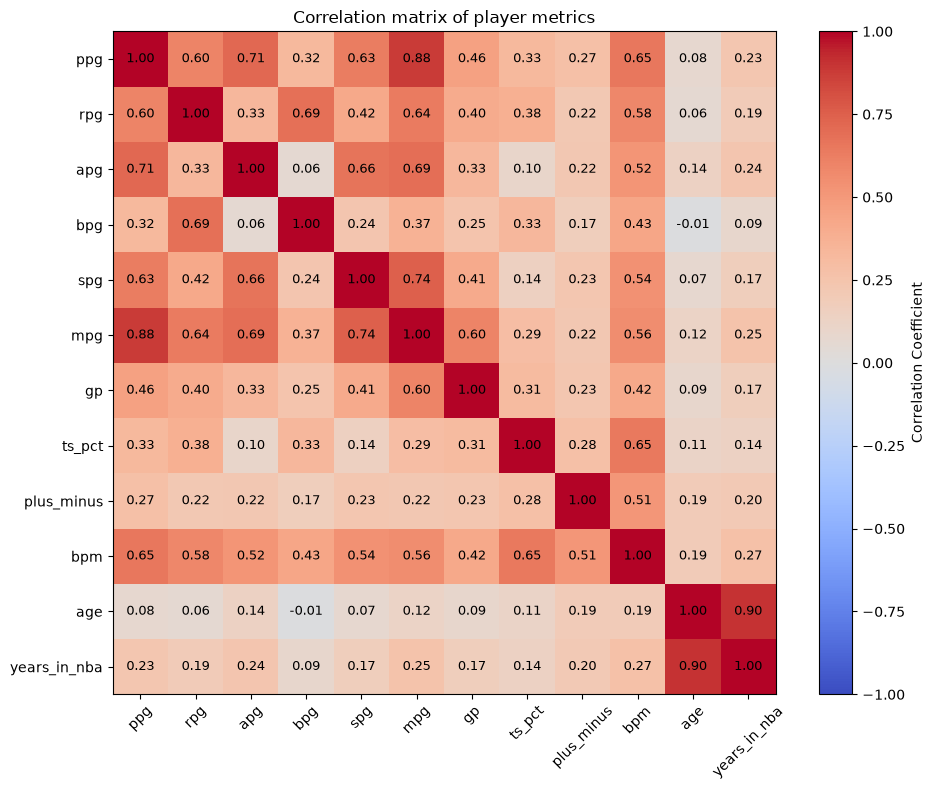


--- Top 5 Strongest Correlation Pairs ---
age & years_in_nba: 0.9005
mpg & ppg: 0.8752
spg & mpg: 0.7426
apg & ppg: 0.7139
apg & mpg: 0.6904

Correlation of ppg with plus_minus: 0.27, with bpm: 0.65
20+ ppg scorers: 432, with negative plus_minus: 26%, with negative bpm: 7%


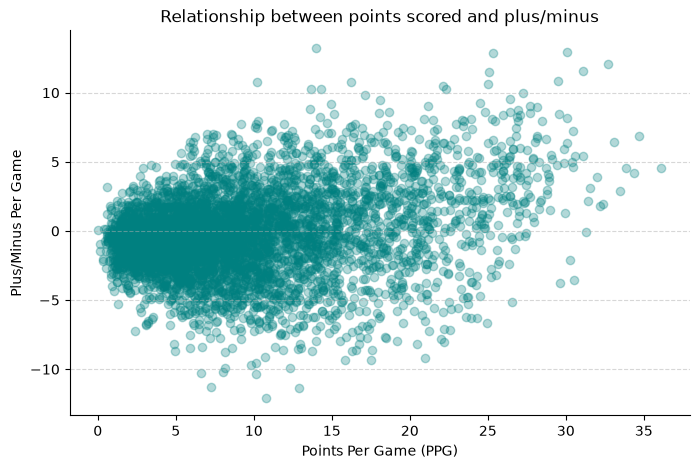

In [4]:
# Columns to include in heatmap
eda_corr_cols = ['ppg', 'rpg', 'apg', 'bpg', 'spg', 'mpg', 'gp', 'ts_pct', 'plus_minus', 'bpm', 'age', 'years_in_nba']

# Compute correlation matrix on rows without suspicious entries
eda_corr_matrix = eda_no_susp[eda_corr_cols].corr()

# Plot heatmap with matplotlib imshow
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(eda_corr_matrix.values, cmap='coolwarm', vmin=-1, vmax=1)

# Add values inside cells
for i in range(len(eda_corr_cols)):
    for j in range(len(eda_corr_cols)):
        text = ax.text(j, i, f"{eda_corr_matrix.iloc[i, j]:.2f}",
                       ha="center", va="center", color="black", fontsize=9)

ax.set_xticks(range(len(eda_corr_cols)))
ax.set_yticks(range(len(eda_corr_cols)))
ax.set_xticklabels(eda_corr_cols, rotation=45)
ax.set_yticklabels(eda_corr_cols)
fig.colorbar(im, ax=ax, label='Correlation Coefficient')
plt.title('Correlation matrix of player metrics')
plt.tight_layout()
plt.show()

# Find top 5 strongest pairs
eda_flat_corr = eda_corr_matrix.abs().unstack()
# Remove diagonal self-pairs
eda_flat_corr = eda_flat_corr[eda_flat_corr < 0.9999]
# Get unique values
eda_top_pairs = eda_flat_corr.sort_values(ascending=False).drop_duplicates().head(5)
print("\n--- Top 5 Strongest Correlation Pairs ---")
for idx, val in eda_top_pairs.items():
    # Get original signed value
    signed_val = eda_corr_matrix.loc[idx[0], idx[1]]
    print(f"{idx[0]} & {idx[1]}: {signed_val:.4f}")

eda_scorers = eda_no_susp[eda_no_susp['ppg'] >= 20]
print(f"\nCorrelation of ppg with plus_minus: {eda_no_susp['ppg'].corr(eda_no_susp['plus_minus']):.2f}, with bpm: {eda_no_susp['ppg'].corr(eda_no_susp['bpm']):.2f}")
print(f"20+ ppg scorers: {len(eda_scorers)}, with negative plus_minus: {(eda_scorers['plus_minus'] < 0).mean():.0%}, with negative bpm: {(eda_scorers['bpm'] < 0).mean():.0%}")

# Scatter: ppg vs plus_minus
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(eda['ppg'], eda['plus_minus'], alpha=0.3, color='teal')
ax.set_title('Relationship between points scored and plus/minus')
ax.set_xlabel('Points Per Game (PPG)')
ax.set_ylabel('Plus/Minus Per Game')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.show()

### What we found

* **Strongest pairs:** `age` & `years_in_nba` (0.90), `ppg` & `mpg` (0.88), `spg` & `mpg` (0.74), `apg` & `ppg` (0.71), `apg` & `mpg` (0.69).
* **Collinearity:** age and years in the NBA carry very similar information, and most box-score stats go up with minutes. This matters for modeling.
* **Scoring vs impact:** scoring is only loosely related to on-court plus/minus (correlation 0.27; the scatter has a lot of spread), but strongly related to BPM (0.65). Of the 432 player-seasons with 20+ `ppg`, 26% have a negative `plus_minus`, but only 7% have a negative `bpm`. On-court plus/minus depends on teammates and opponents, while BPM is built from the player's own box score. That is why the pipeline uses BPM for the Box +/- feature.

## 5. League changes over time

Do the averages shift across the 11 seasons (2016 to 2026)?

season,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mean_ppg,8.775,8.945,8.915,9.282,9.535,9.444,9.351,9.855,9.246,9.560,9.92
mean_ts_pct,0.530,0.537,0.540,0.544,0.553,0.556,0.552,0.568,0.564,0.561,0.57
row_count,441.000,445.000,468.000,469.000,460.000,490.000,500.000,470.000,497.000,508.000,506.00


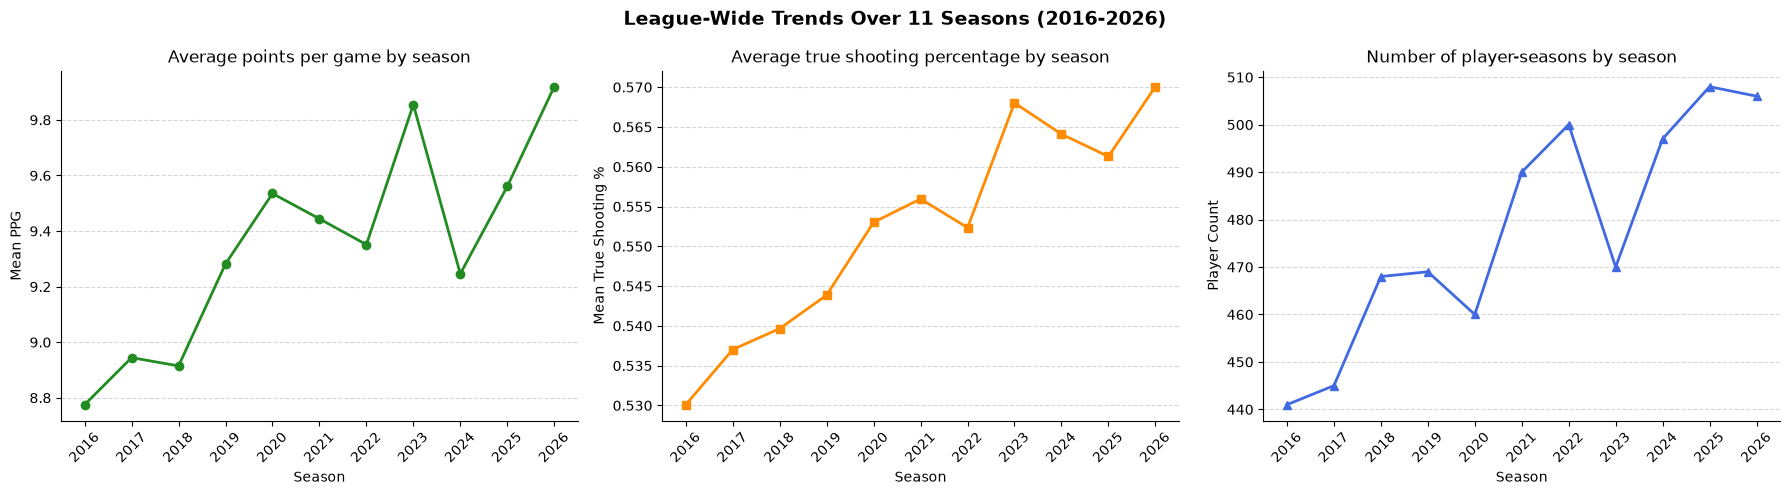

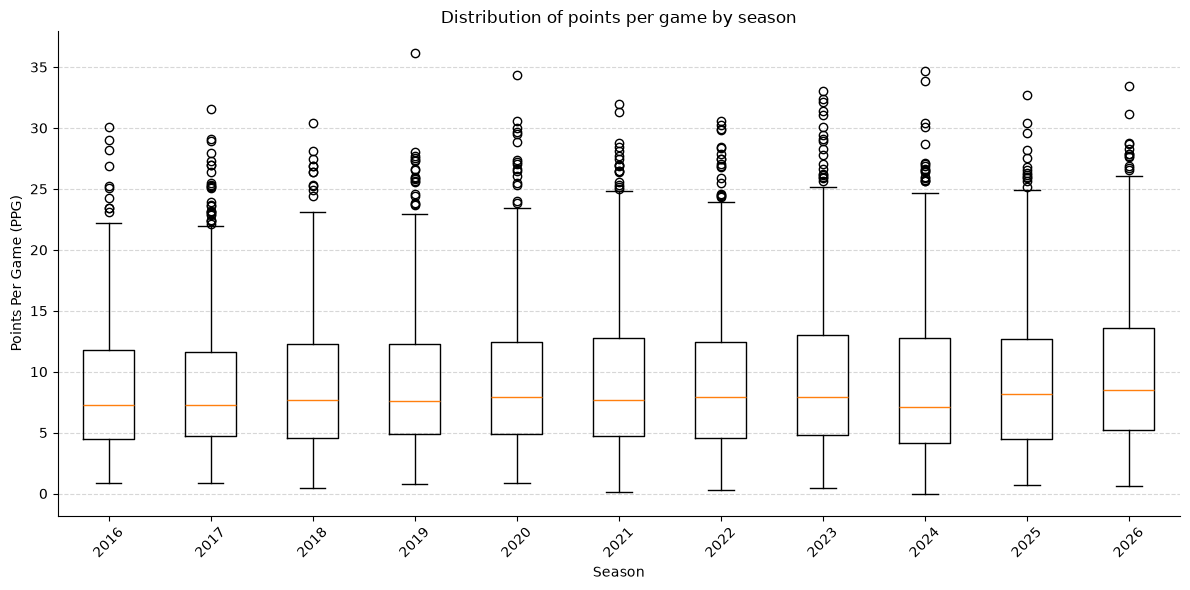

In [5]:
# Line charts by season
eda_season_trends = eda.groupby('season').agg(
    mean_ppg=('ppg', 'mean'),
    mean_ts_pct=('ts_pct', 'mean'),
    row_count=('player_id', 'count')
).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Mean PPG
axes[0].plot(eda_season_trends.index, eda_season_trends['mean_ppg'], marker='o', color='forestgreen', linewidth=2)
axes[0].set_title('Average points per game by season')
axes[0].set_xlabel('Season')
axes[0].set_ylabel('Mean PPG')

# Mean True Shooting
axes[1].plot(eda_season_trends.index, eda_season_trends['mean_ts_pct'], marker='s', color='darkorange', linewidth=2)
axes[1].set_title('Average true shooting percentage by season')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Mean True Shooting %')

# Number of Players
axes[2].plot(eda_season_trends.index, eda_season_trends['row_count'], marker='^', color='royalblue', linewidth=2)
axes[2].set_title('Number of player-seasons by season')
axes[2].set_xlabel('Season')
axes[2].set_ylabel('Player Count')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    ax.set_xticks(eda_season_trends.index)
    ax.set_xticklabels([str(x) for x in eda_season_trends.index], rotation=45)

display(eda_season_trends.round(3).T)
plt.suptitle('League-Wide Trends Over 11 Seasons (2016-2026)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Boxplot of ppg by season
fig, ax = plt.subplots(figsize=(12, 6))
eda_seasons = sorted(eda['season'].unique())
eda_ppg_data = [eda[eda['season'] == s]['ppg'] for s in eda_seasons]

ax.boxplot(eda_ppg_data, tick_labels=eda_seasons)
ax.set_title('Distribution of points per game by season')
ax.set_xlabel('Season')
ax.set_ylabel('Points Per Game (PPG)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What we found

* **Shooting efficiency:** average `ts_pct` goes from 53.0% in 2016 to 57.0% in 2026. The rise is not smooth (it dips in 2022, 2024, and 2025), but the overall direction is up.
* **Scoring:** average `ppg` goes from 8.8 in 2016 to 9.9 in 2026, so it also drifts up a little.
* **Player-seasons per season:** the count (players with 10+ games) is lowest in 2016 (441), highest in 2025 (508), and 506 in 2026.

## 6. The 3-year average columns

The pipeline's `avg_*_last_3` columns average a player's **three previous regular seasons** (season − 3 to season − 1). The current season is not included, and `seasons_played_last_3` (0-3) counts how many of those seasons he played. So "this season minus the 3-year average" is a real change from his recent past.

Here we use rows where the player played all three previous seasons (`seasons_played_last_3 == 3`) and there's no suspicious entry. Then we look at who has fewer than three.

Number of records with all 3 previous seasons: 2963


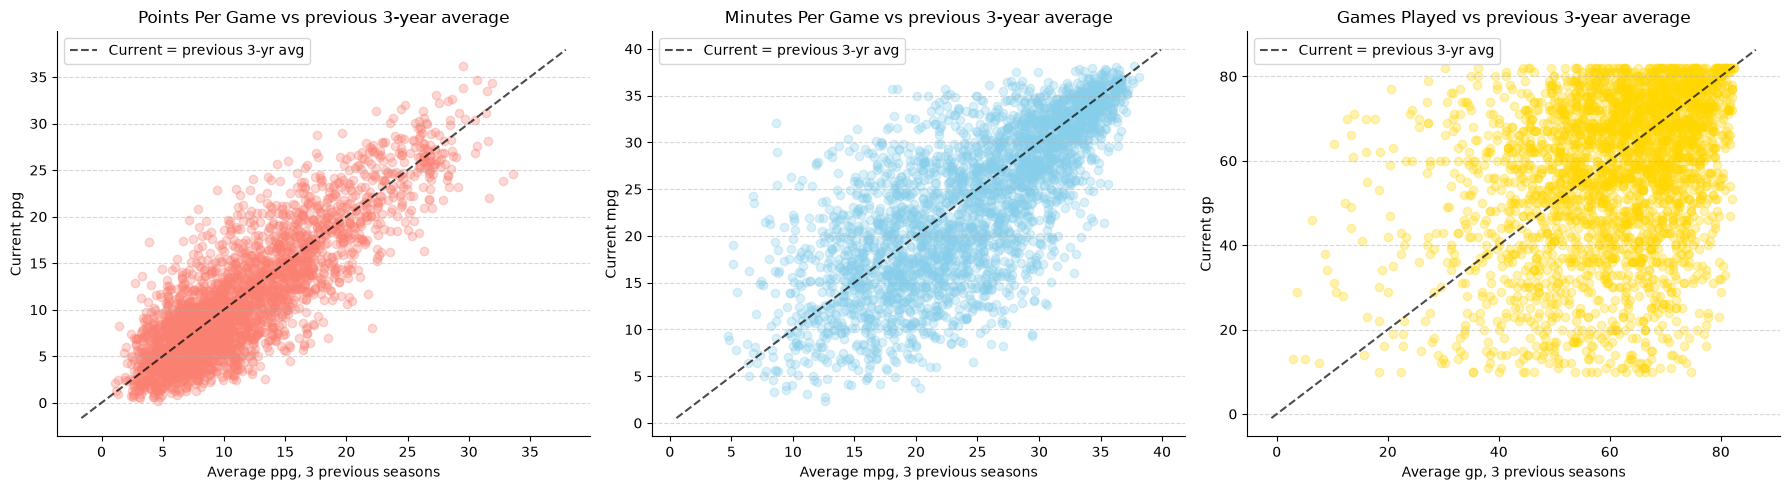


--- Summary Stats for PPG & GP Changes ---


,eda_ppg_change,eda_gp_change
count,2963.000,2963.000
mean,-0.362,-3.377
std,3.557,18.953
min,-14.034,-64.667
25%,-2.678,-14.667
50%,-0.570,-1.333
75%,1.854,9.000
max,13.466,57.333


Players scoring at least 3 PPG above their previous 3-yr average: 480 (16.2%)
Players scoring at least 3 PPG below their previous 3-yr average: 648 (21.9%)

Rows with no average (0 previous seasons): 830 (15.8%)
--- Share of rows (%) by number of previous seasons, by experience group ---


seasons_played_last_3,0.0,1.0,2.0,3.0
exp_bin,,,,
1 (Rookie),100.0,0.0,0.0,0.0
2,0.0,100.0,0.0,0.0
3,0.2,1.9,98.0,0.0
4-5,0.2,1.3,4.3,94.2
6-9,0.5,1.6,4.1,93.8
10+,0.3,1.0,2.9,95.7


In [6]:
# Rows whose previous 3 seasons are all in the table (the closest match to a "full window"), no suspicious entries
eda_trend = eda[(eda['seasons_played_last_3'] == 3) & (eda['suspicious_entry'] == False)].copy()
print(f"Number of records with all 3 previous seasons: {len(eda_trend)}")

# 1. Scatter plots comparing current values to the average of the 3 previous seasons
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = [('ppg', 'avg_ppg_last_3', 'Points Per Game', 'salmon'),
           ('mpg', 'avg_mpg_last_3', 'Minutes Per Game', 'skyblue'),
           ('gp', 'avg_gp_last_3', 'Games Played', 'gold')]

for i, (col, avg_col, name, color) in enumerate(metrics):
    axes[i].scatter(eda_trend[avg_col], eda_trend[col], alpha=0.3, color=color)
    lims = [
        np.min([axes[i].get_xlim(), axes[i].get_ylim()]),
        np.max([axes[i].get_xlim(), axes[i].get_ylim()])
    ]
    axes[i].plot(lims, lims, 'k--', alpha=0.7, label='Current = previous 3-yr avg')
    axes[i].set_title(f'{name} vs previous 3-year average')
    axes[i].set_xlabel(f'Average {col}, 3 previous seasons')
    axes[i].set_ylabel(f'Current {col}')
    axes[i].legend()
    axes[i].spines['top'].set_visible(False)
    axes[i].spines['right'].set_visible(False)
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 2. Change distributions
eda_trend['eda_ppg_change'] = eda_trend['ppg'] - eda_trend['avg_ppg_last_3']
eda_trend['eda_gp_change'] = eda_trend['gp'] - eda_trend['avg_gp_last_3']

print("\n--- Summary Stats for PPG & GP Changes ---")
display(eda_trend[['eda_ppg_change', 'eda_gp_change']].describe().round(3))

ppg_up_3 = (eda_trend['eda_ppg_change'] >= 3).sum()
ppg_down_3 = (eda_trend['eda_ppg_change'] <= -3).sum()
print(f"Players scoring at least 3 PPG above their previous 3-yr average: {ppg_up_3} ({ppg_up_3 / len(eda_trend):.1%})")
print(f"Players scoring at least 3 PPG below their previous 3-yr average: {ppg_down_3} ({ppg_down_3 / len(eda_trend):.1%})")

# 3. Who has no average at all, or only 1-2 previous seasons?
def experience_bins(y):
    if y == 1:
        return '1 (Rookie)'
    elif y == 2:
        return '2'
    elif y == 3:
        return '3'
    elif y <= 5:
        return '4-5'
    elif y <= 9:
        return '6-9'
    else:
        return '10+'

eda['exp_bin'] = eda['years_in_nba'].apply(experience_bins)
print(f"\nRows with no average (0 previous seasons): {(eda['seasons_played_last_3'] == 0).sum()} "
      f"({(eda['seasons_played_last_3'] == 0).mean():.1%})")
print("--- Share of rows (%) by number of previous seasons, by experience group ---")
display((pd.crosstab(eda['exp_bin'], eda['seasons_played_last_3'], normalize='index') * 100)
        .reindex(['1 (Rookie)', '2', '3', '4-5', '6-9', '10+']).round(1))

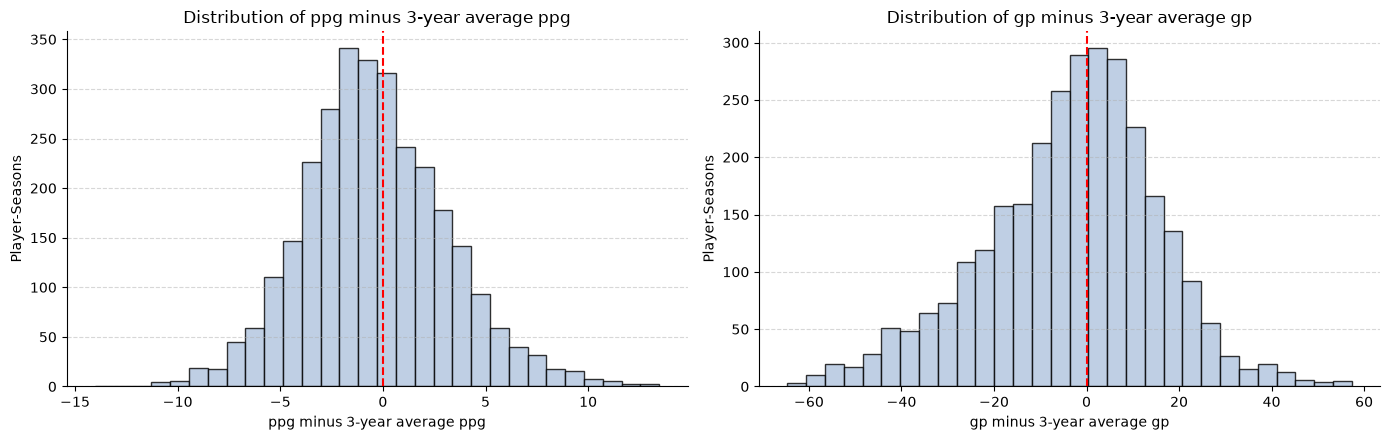

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col, name in zip(axes, ['eda_ppg_change', 'eda_gp_change'],
                         ['ppg minus 3-year average ppg', 'gp minus 3-year average gp']):
    ax.hist(eda_trend[col], bins=30, color='lightsteelblue', edgecolor='black', alpha=0.8)
    ax.axvline(0, color='red', linestyle='--')
    ax.set_title(f'Distribution of {name}')
    ax.set_xlabel(name)
    ax.set_ylabel('Player-Seasons')
    ax.spines[['top', 'right']].set_visible(False)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### What we found

* **Most players stay close to their recent level, with a slight decline:** across 2,963 player-seasons with all three previous seasons, `ppg` is on average 0.36 below the previous 3-year average (median −0.57), with the middle half between −2.68 and +1.85.
* **Drops are more common than rises:** 648 player-seasons (21.9%) are at least 3 `ppg` below the previous average, and 480 (16.2%) at least 3 above. Players with three straight seasons behind them are mostly veterans, and many are past their peak. Games played move a lot more (standard deviation 19 games), because injuries and role changes hit games played directly.
* **Why this is larger than in the earlier EDA:** the old 3-year columns included the current season, which shrank every difference by a third. These averages leave the current season out, so the differences are the full change.
* **Missing averages are only rookies:** 830 rows (15.8%) have no average, and they are all first-year players. Every second-year player has exactly 1 previous season, 98% of third-year players have 2, and 94-96% of players in year 4 or later have all 3. The few exceptions missed a season (injuries, time away from the league). A model can use `seasons_played_last_3` to know how much history is behind each average.

## 7. Players who stay vs players who appear and disappear

How many seasons does each player appear in this table, and how do short-career players differ from veterans?

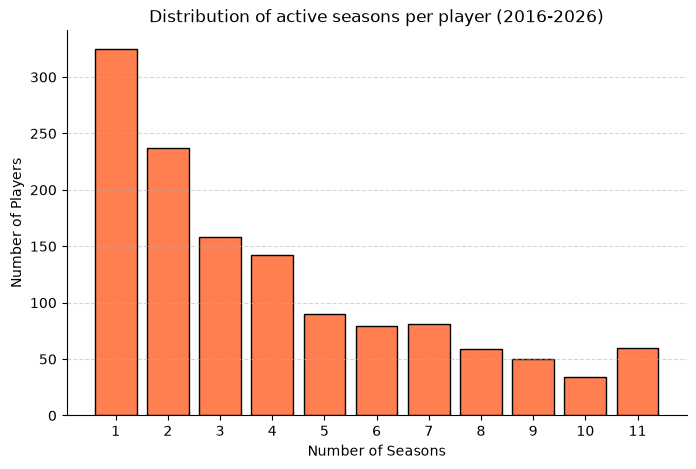

Players: 1,315; with only 1-2 seasons: 562 (43%)
Share of total player-seasons belonging to players with only 1-2 seasons: 15.21%


,ppg,mpg,age,years_in_nba
career_length_group,,,,
Short-career (1-2 seasons),4.176471,12.475144,24.0,2.0
Long-career (6+ seasons),10.213333,25.408699,27.0,6.0


In [8]:
# 1. Count seasons per player
player_season_counts = eda.groupby('player_name')['season'].count()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(player_season_counts, bins=range(1, 13), align='left', color='coral', edgecolor='black', rwidth=0.8)
ax.set_title('Distribution of active seasons per player (2016-2026)')
ax.set_xlabel('Number of Seasons')
ax.set_ylabel('Number of Players')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_xticks(range(1, 12))
plt.show()

# 2. Share of player-seasons belonging to 1-2 season players
short_career_players = player_season_counts[player_season_counts <= 2].index
short_career_share = eda['player_name'].isin(short_career_players).mean() * 100
print(f"Players: {len(player_season_counts):,}; with only 1-2 seasons: {len(short_career_players):,} ({len(short_career_players) / len(player_season_counts):.0%})")
print(f"Share of total player-seasons belonging to players with only 1-2 seasons: {short_career_share:.2f}%")

# 3. Compare statistics
eda['career_length_group'] = eda['player_name'].apply(
    lambda x: 'Short-career (1-2 seasons)' if player_season_counts[x] <= 2
    else ('Long-career (6+ seasons)' if player_season_counts[x] >= 6 else 'Medium-career')
)

career_comparison = eda.groupby('career_length_group')[['ppg', 'mpg', 'age', 'years_in_nba']].median()
display(career_comparison.reindex(['Short-career (1-2 seasons)', 'Long-career (6+ seasons)']))

### What we found

* **Short careers in the table:** 562 of 1,315 players (43%) appear in only 1-2 seasons, and they make up 15.2% of all player-seasons.
* **Difference:** players with 6+ seasons have a median of 10.2 `ppg` and 25.4 `mpg`, compared with 4.2 `ppg` and 12.5 `mpg` for players with 1-2 seasons. The short group is also younger (median age 24 vs 27) and less experienced (median 2 years vs 6).
* **Be careful:** this counts seasons only inside 2016-2026, and only seasons with 10+ games. A player who debuted in 2025 or retired in 2017 looks "short" even if his career was long. So this isn't proof that weaker players have shorter careers.

## 8. Summary of the EDA

* **Production stats are right-skewed:** `ppg`, `rpg`, `apg`, and `bpg` have long right tails, so the elite players are a thin group. Medians and rank-based methods describe them better than means.
* **Strong collinearity:** `mpg` and `ppg` correlate at 0.875, and age and experience at 0.90. A trade model probably doesn't need every one of these.
* **BPM measures the player more than on-court plus/minus does:** it correlates 0.65 with scoring (vs 0.27), and only 7% of 20+ `ppg` scorers have a negative BPM (vs 26% for plus/minus).
* **3-year averages are missing only for rookies** (15.8% of rows), now that they average the previous seasons the player actually played. `seasons_played_last_3` shows how much history is behind each one.
* **Year-to-year change:** 21.9% of veterans with three previous seasons drop at least 3 `ppg` below their average, and 16.2% rise at least 3 above it.
* **Next steps for modeling:**
  1. Does a sudden drop or rise relative to a player's previous 3-year average make him more likely to be traded?
  2. Should right-skewed stats be transformed (e.g. logs) before modeling? Tree models like XGBoost don't need it, but simpler baselines might.
  3. Do rookies (no 3-year average) need different handling, or is `seasons_played_last_3 == 0` enough for the model?